In [1]:
from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


In [2]:
# Connect and Access Git Repository

import os
import sys
from getpass import getpass
from pathlib import Path

GITHUB_USERNAME = "sharaffatima"
REPO_NAME = "bachelor-thesis"



token = getpass("GitHub token: ")


REPO_URL = f"https://{token}@github.com/{GITHUB_USERNAME}/{REPO_NAME}.git"
REPO_DIR = Path("/content") / REPO_NAME


if not REPO_DIR.exists():
    !git clone {REPO_URL} {REPO_DIR}
else:
    %cd {REPO_DIR}
    !git pull

%cd {REPO_DIR}
sys.path.append(str(REPO_DIR))

print("Repo exists:", REPO_DIR.exists())

GitHub token: ··········
Cloning into '/content/bachelor-thesis'...
remote: Enumerating objects: 162, done.
remote: Counting objects: 100% (162/162), done.
remote: Compressing objects: 100% (119/119), done.
remote: Total 162 (delta 65), reused 121 (delta 33), pack-reused 0 (from 0)
Receiving objects: 100% (162/162), 961.07 KiB | 3.89 MiB/s, done.
Resolving deltas: 100% (65/65), done.
/content/bachelor-thesis
Repo exists: True


In [3]:
# Imports
import os
import numpy as np
import torch
from torch.utils.data import DataLoader


# global configuration

REPO_DIR = Path("/content/bachelor-thesis")
sys.path.append(str(REPO_DIR))

from utils.dataset import PTBXLAnoFormerDataset
from explainability.attention import AnoFormerExplainability
from utils.seed import set_seed, RANDOM_SEED
from models.anoformer import AnoFormerMainModel

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
set_seed(RANDOM_SEED)
print(f"Active device: {DEVICE}")

Active device: cuda


In [4]:
# Load my preprocessed data

PROCESSED_DIR = Path("/content/drive/MyDrive/ECG data/processed")

X_train = np.load(PROCESSED_DIR / "X_train.npy")
y_train = np.load(PROCESSED_DIR / "y_train.npy")

X_val = np.load(PROCESSED_DIR / "X_val.npy")
y_val = np.load(PROCESSED_DIR / "y_val.npy")

X_test = np.load(PROCESSED_DIR / "X_test.npy")
y_test = np.load(PROCESSED_DIR / "y_test.npy")

print(X_train.shape, y_train.shape)
print(X_val.shape, y_val.shape)
print(X_test.shape, y_test.shape)

(17418, 1000, 12) (17418,)
(2183, 1000, 12) (2183,)
(2198, 1000, 12) (2198,)


In [5]:
# Training only on normal data

normal_train_mask = y_train == 0

X_train_normal = X_train[normal_train_mask]
y_train_normal = y_train[normal_train_mask]

print("Training on normal ECGs:", X_train_normal.shape)

Training on normal ECGs: (7596, 1000, 12)


In [6]:
# Datasets

train_dataset = PTBXLAnoFormerDataset(
    X_train_normal,
    y_train_normal,
    normalize=True
)

val_dataset = PTBXLAnoFormerDataset(
    X_val,
    y_val,
    mean=train_dataset.mean,
    std=train_dataset.std,
    normalize=True
)

test_dataset = PTBXLAnoFormerDataset(
    X_test,
    y_test,
    mean=train_dataset.mean,
    std=train_dataset.std,
    normalize=True
)

In [7]:
# Dataloaders

train_loader = DataLoader(
    train_dataset,
    batch_size=4,
    shuffle=True,
    drop_last=True,
    num_workers=2,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=4,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=4,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

In [8]:
# Check the shapes

# Expected:
#         Batch X: torch.Size([16, 1000, 12])
#         Batch y: torch.Size([16])

batch_x, batch_y = next(iter(train_loader))

print(batch_x.shape)
print(batch_y.shape)

torch.Size([4, 1000, 12])
torch.Size([4])


In [9]:
# Create Model

AnoFormer = AnoFormerMainModel(
    NumFeatures=12,
    ModelDimension=32,
    NumHeads=4,
    NumEncoderLayers=1,
    NumDecoderLayers=1,
    DiscriminatorLayers=1,
    ForwardDimension=64,
    DropoutRate=0.1,
    GeneratorLearningRate=1e-4,
    DiscriminatorLearningRate=1e-4,
    MaskingRate=0.15,
    AnomalyThreshold=0.75,
    ReconstructionWeight=10.0,
)

In [10]:
batch_x, _ = next(iter(train_loader))
batch_x = batch_x.to(AnoFormer.Device)

with torch.no_grad():
    masked_x, _ = AnoFormer.Masking(batch_x, None)
    reconstruction = AnoFormer.Generator(masked_x)

print("Input:", batch_x.shape)
print("Masked:", masked_x.shape)
print("Reconstruction:", reconstruction.shape)

Input: torch.Size([4, 1000, 12])
Masked: torch.Size([4, 1000, 12])
Reconstruction: torch.Size([4, 1000, 12])


In [11]:
# Training

print("\n── AnoFormer Training starts ─────────────────────────────")

AnoFormer.TrainModel(
    TrainingLoader=train_loader,
    NumEpochs=5,
    PrintInterval=1,
)


── AnoFormer Training starts ─────────────────────────────
Epoche    1/5 | G-Total=8.7455 | G-GAN=1.4709 | G-Rec=0.7275 | D=0.4644
Epoche    2/5 | G-Total=11.4439 | G-GAN=1.6011 | G-Rec=0.9843 | D=0.3939
Epoche    3/5 | G-Total=5.3611 | G-GAN=0.8490 | G-Rec=0.4512 | D=0.6791
Epoche    4/5 | G-Total=11.3939 | G-GAN=1.9160 | G-Rec=0.9478 | D=0.3195
Epoche    5/5 | G-Total=4.9797 | G-GAN=0.7984 | G-Rec=0.4181 | D=0.7031
Training abgeschlossen.


In [12]:
# Anomaly Detection

print("\n── AnoFormer Anomaly Detection ───────────────────────────")

AnomalyScores, BinaryPredictions = AnoFormer.DetectAnomalies(test_loader)

print("Scores shape:", AnomalyScores.shape)
print("Predictions shape:", BinaryPredictions.shape)
print("Detected anomalous ECG records:", BinaryPredictions.sum())


── AnoFormer Anomaly Detection ───────────────────────────
Scores shape: (2198,)
Predictions shape: (2198,)
Detected anomalous ECG records: 110


In [13]:
# Evaluation

from sklearn.metrics import confusion_matrix, classification_report, roc_auc_score, average_precision_score

print(confusion_matrix(y_test, BinaryPredictions))
print(classification_report(y_test, BinaryPredictions))

print("ROC-AUC:", roc_auc_score(y_test, AnomalyScores))
print("PR-AUC:", average_precision_score(y_test, AnomalyScores))

[[ 944   19]
 [1144   91]]
              precision    recall  f1-score   support

           0       0.45      0.98      0.62       963
           1       0.83      0.07      0.14      1235

    accuracy                           0.47      2198
   macro avg       0.64      0.53      0.38      2198
weighted avg       0.66      0.47      0.35      2198

ROC-AUC: 0.6318917350889806
PR-AUC: 0.6976998970509443


In [14]:
# Evaluation

print("\n── AnoFormer Evaluation ───────────────────────")

Metrics = AnoFormer.Evaluate(test_loader, y_test)
print(Metrics)


── AnoFormer Evaluation ───────────────────────
  Precision           : 0.8246
  Recall              : 0.0761
  F1Score             : 0.1394
  Threshold           : 1.210747
  TruePositive        : 94
  FalsePositive       : 20
  FalseNegative       : 1141
{'Precision': 0.8246, 'Recall': 0.0761, 'F1Score': 0.1394, 'Threshold': 1.210747, 'TruePositive': 94, 'FalsePositive': 20, 'FalseNegative': 1141}



── AnoFormer Explainability ───────────────────


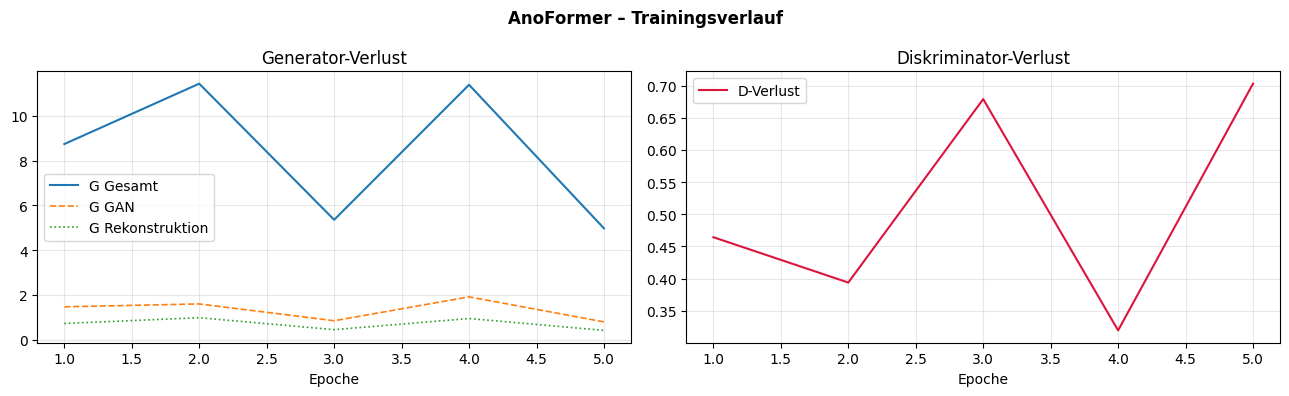

FirstBatch shape: torch.Size([4, 1000, 12])


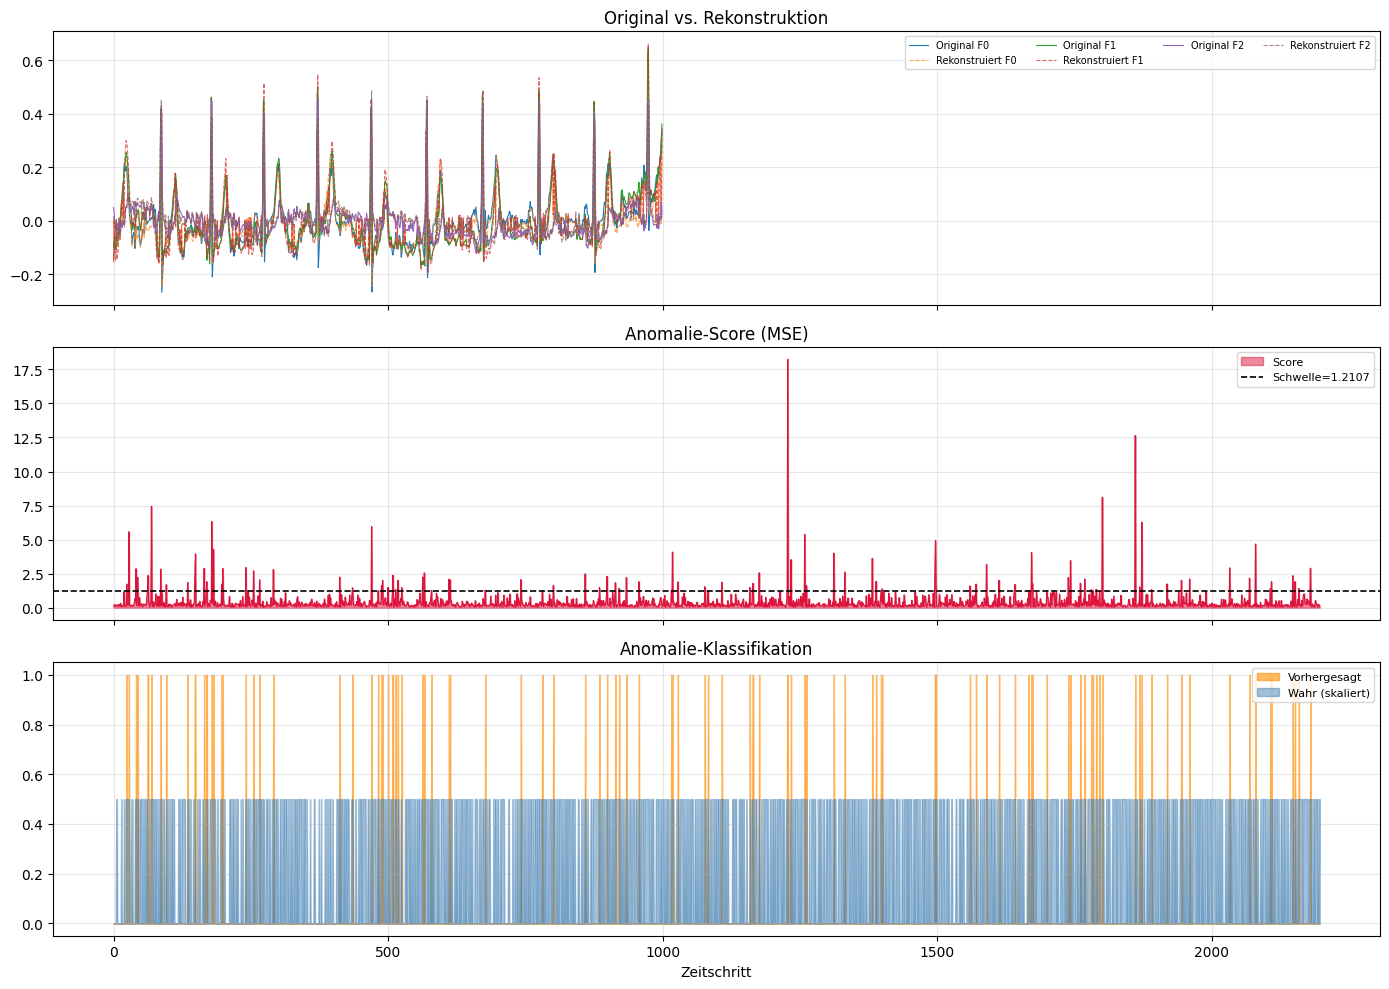

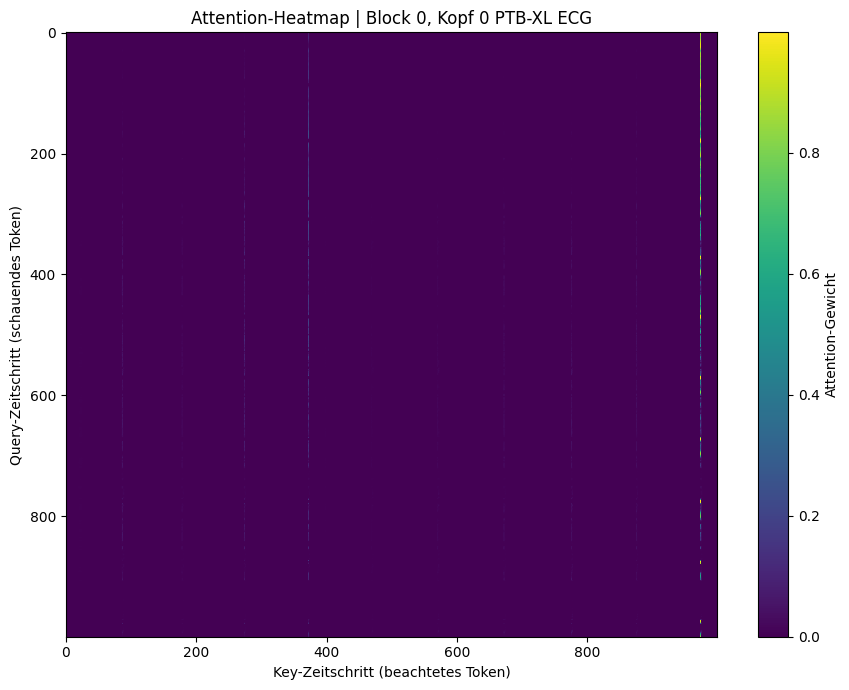

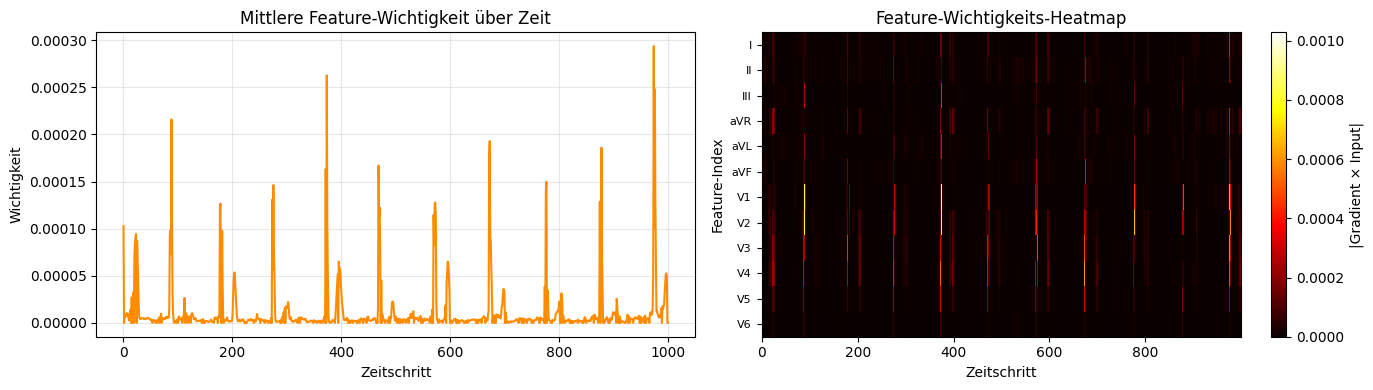


AnoFormer PTB-XL explainability complete.


In [15]:
# Explainability

print("\n── AnoFormer Explainability ───────────────────")

Explainer = AnoFormerExplainability(AnoFormer)

# Training history
Explainer.ShowTrainingHistory()

# First ECG batch
FirstBatch, _ = next(iter(test_loader))
FirstBatch = FirstBatch.to(AnoFormer.Device)

print("FirstBatch shape:", FirstBatch.shape)

# Reconstruction
with torch.no_grad():
    Masked, _ = AnoFormer.Masking(FirstBatch, None)
    Reconstructed = AnoFormer.Generator(Masked)

# Inverse normalization
OriginalNP = test_dataset.InverseNormalization(
    FirstBatch[0].cpu().numpy()
)

ReconstructedNP = test_dataset.InverseNormalization(
    Reconstructed[0].cpu().numpy()
)

# Reconstruction error visualization
Explainer.ShowReconstructionError(
    OriginalData      = OriginalNP,
    ReconstructedData = ReconstructedNP,
    AnomalyScores     = AnomalyScores,
    TrueLabels        = y_test,
    Threshold         = AnoFormer.AnomalyLimit,
)

# One ECG record for attention / feature importance
OneECG = FirstBatch[:1]   # (1, 1000, 12)

Explainer.ShowAttentionHeatmap(
    OneECG,
    BlockIndex=0,
    HeadIndex=0,
    TitleSuffix="PTB-XL ECG"
)

ECG_LEADS = [
    "I", "II", "III",
    "aVR", "aVL", "aVF",
    "V1", "V2", "V3", "V4", "V5", "V6"
]

Explainer.ShowFeatureImportance(
    OneECG,
    FeatureNames=ECG_LEADS
)

print("\nAnoFormer PTB-XL explainability complete.")